# Cycles in business, labour and commodity markets in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/15-cycles.ipynb)

Why do firms, labour markets and commodity markets go through booms and busts even when nobody outside shocks them? This notebook builds the answer from LoopBricks molecules: [Workforce](https://waelrash1.github.io/loopbricks/#/m/workforce), [Desired Workforce](https://waelrash1.github.io/loopbricks/#/m/desiredWorkforce), [Low-Visibility Pipeline](https://waelrash1.github.io/loopbricks/#/m/lowVisPipeline), [Overtime](https://waelrash1.github.io/loopbricks/#/m/overtime), [Smooth Pricing](https://waelrash1.github.io/loopbricks/#/m/smoothPricing) and [Sea Anchor Pricing](https://waelrash1.github.io/loopbricks/#/m/seaAnchorPricing). You will treat labour as a stock, watch a firm cycle because it forgets what is already on order, see overtime absorb a shortfall, and compare two ways of setting a price.

It goes with the [Cycles module](https://waelrash1.github.io/loopbricks/#/learn/cycles) in the app.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Labour is a stock

People are hired and released, and the workforce is what those two flows leave behind. A firm that decides it needs more people cannot have them today: the gap is closed by hiring, a little at a time. In **Workforce**, hiring each year is the gap between desired and actual workforce divided by the time to hire or fire.

**Desired Workforce** adds where the target comes from: the work to be done divided by what one person can do. Watch the hiring rate, not just the workforce.

             Workforce
time (year)           
0.0               40.0
4.0               65.5
8.0               74.7
12.0              78.1
20.0              79.7

Hiring starts at 5.0 people a week and is down to 0.24 by week 12


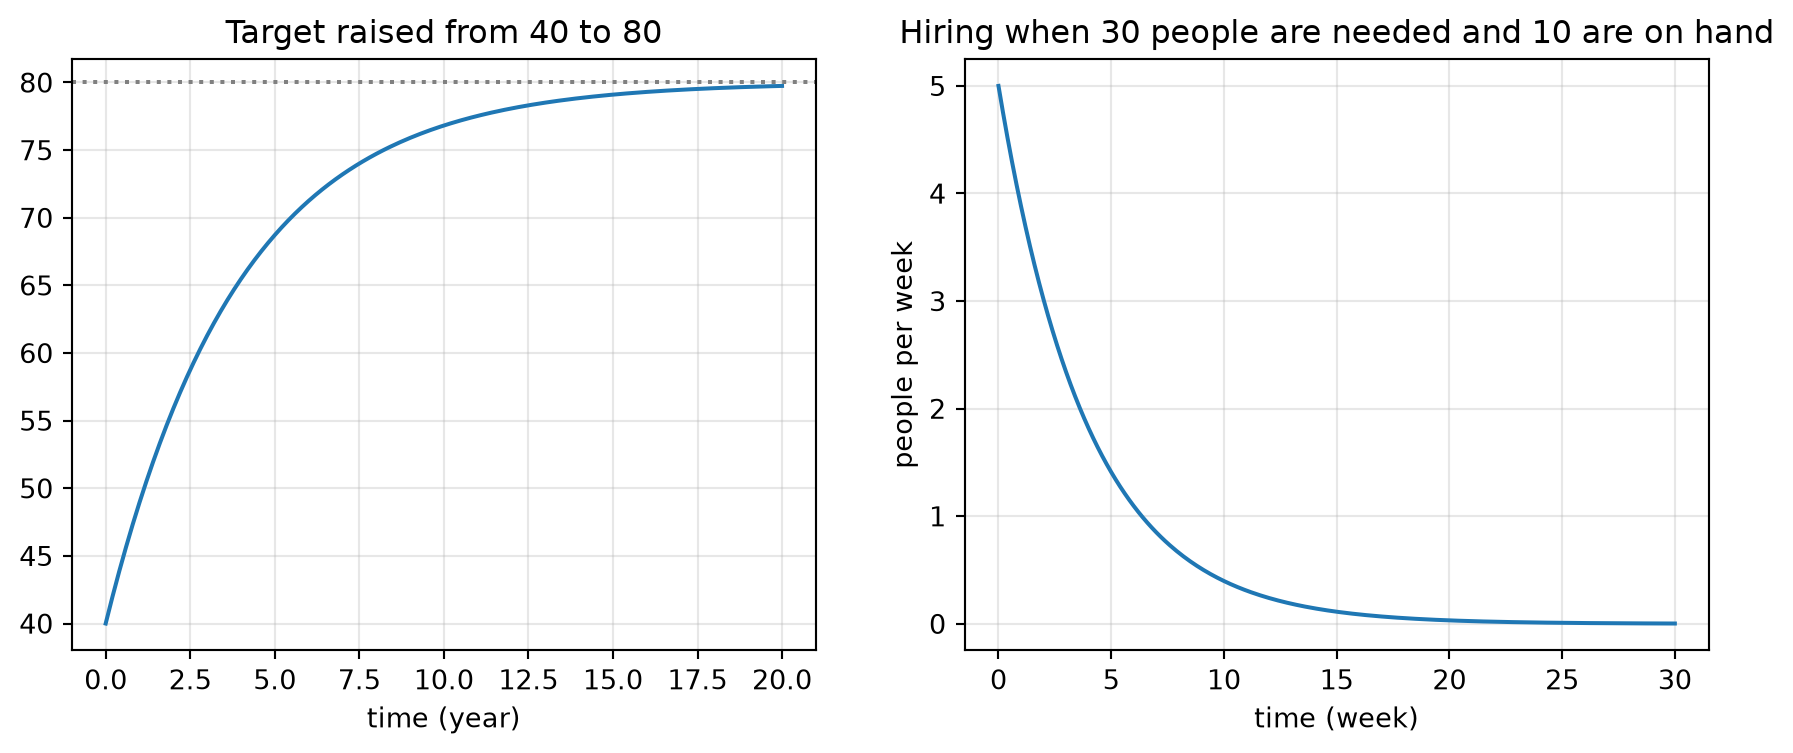

In [2]:
wf = lb.molecule("workforce")
dw = lb.molecule("desiredWorkforce")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ramp = wf.run(T=20, desired_workforce=80)
ramp["Workforce"].plot(ax=ax1)
ax1.axhline(80, ls=":", c="grey"); ax1.set_title("Target raised from 40 to 80"); ax1.grid(alpha=0.3)

team = dw.run(T=30)
team["Hiring"].plot(ax=ax2)
ax2.set_title("Hiring when 30 people are needed and 10 are on hand"); ax2.set_ylabel("people per week"); ax2.grid(alpha=0.3)

print(ramp.loc[[0, 4, 8, 12, 20], ["Workforce"]].round(1))
print(f"\nHiring starts at {team['Hiring'].iloc[0]:.1f} people a week and is down to {team.loc[12.0, 'Hiring']:.2f} by week 12")

The workforce closes the gap fast at first and then ever more slowly: from 40 to about 65 after one hiring time (4 years), then 75 and 78. In the second run 120 tasks a week at 4 tasks a person calls for 30 people. Hiring jumps at once to (30 − 10) / 4 = 5 people a week, half the size of the existing team, and then fades. Most of the load on the recruiting department lands at the very start. That burst is the first ingredient of a cycle: a modest change in what the firm wants turns into a large, sudden demand on hiring.

**Try it.** Now the work falls to 20 tasks a week, so only 5 people are needed. How long does the team take to get within one person of that target? Is shrinking slower than growing in this molecule?

<details><summary>Show a worked answer</summary>

The next cell runs it. The team falls from 10 to 6 by week 6.4 and is about 5.2 by week 12. Growing from 10 to within one person of 30 takes until week 11.9. Both are the same first-order adjustment with a 4-week time constant, so in this molecule cuts are simply hiring in reverse. Real firms are rarely like that: many will not lay people off and can shrink only as people leave, which is much slower. Testing a model in both directions is how you find out whether it needs that extra structure.
</details>

In [3]:
cut = dw.run(T=30, desired_accomplishing_rate=20)
print("Team down to 6 by week", cut.index[cut["Workforce"] <= 6][0], f"; at week 12 it is {cut.loc[12.0, 'Workforce']:.2f}")
print("Growing: within one person of 30 by week", team.index[team["Workforce"] >= 29][0])

Team down to 6 by week 6.4 ; at week 12 it is 5.24
Growing: within one person of 30 by week 11.9


## 2. The pipeline nobody counts

Hiring takes time, and so does ordering goods. Whatever has been requested but has not yet arrived sits in a supply line: vacancies not yet filled, orders not yet delivered. In **Low-Visibility Pipeline** a firm orders to replace what it ships, to correct its inventory, and to keep the right amount on order. The `Awareness of pipeline` says how much attention the firm pays to that last part (1 is full attention, 0 is none).

awareness 1: peaks []


awareness 0.5: peaks [(17.6, 102.9), (43.8, 100.0), (70.0, 100.0)]
awareness 0: peaks [(16.4, 117.2), (45.2, 103.8), (74.1, 100.8)]


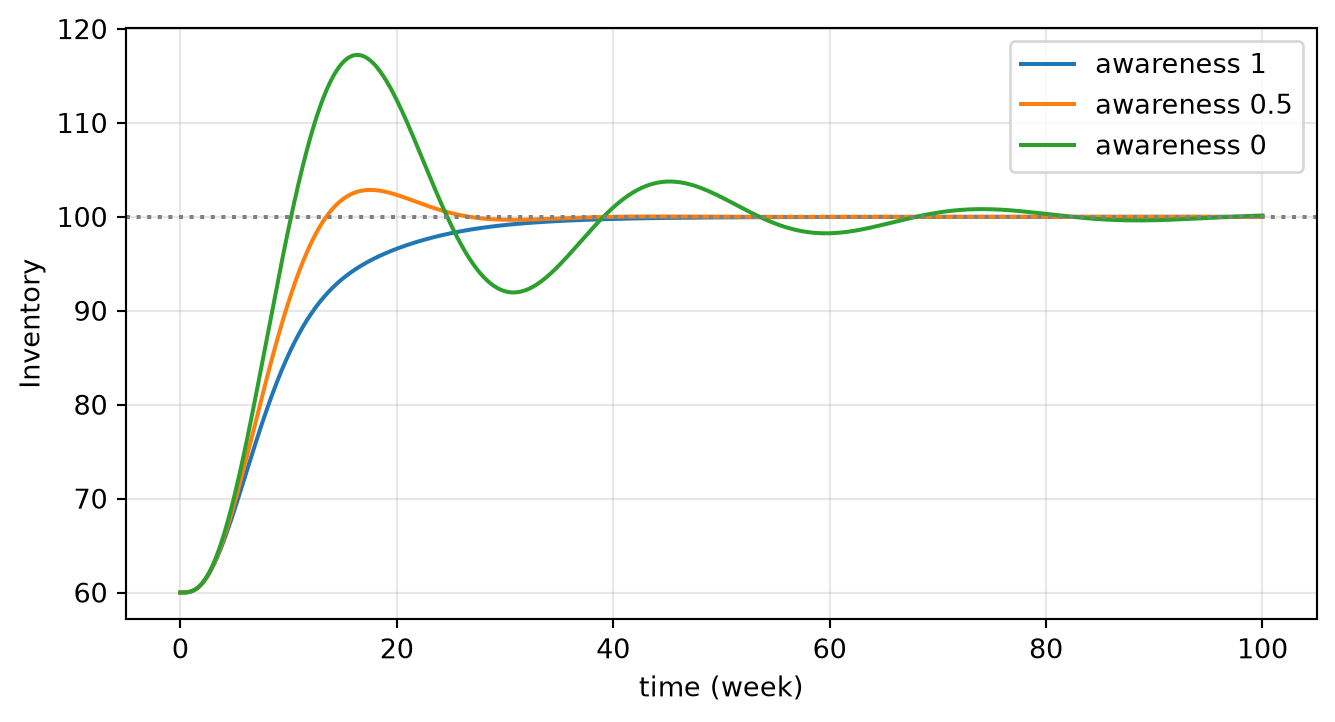

In [4]:
lv = lb.molecule("lowVisPipeline")

def turning_points(series):
    """Times and values of the local peaks of a series."""
    v, t = series.values, series.index
    return [(float(t[i]), round(float(v[i]), 1)) for i in range(1, len(v) - 1) if v[i - 1] < v[i] >= v[i + 1]]

fig, ax = plt.subplots(figsize=(8, 4))
for aware in (1, 0.5, 0):
    inv = lv.run(T=100, awareness_of_pipeline=aware)["Inventory"]
    inv.plot(ax=ax, label=f"awareness {aware}")
    print(f"awareness {aware}: peaks {turning_points(inv)[:3]}")
ax.axhline(100, ls=":", c="grey"); ax.set_ylabel("Inventory"); ax.legend(); ax.grid(alpha=0.3)

With full awareness, inventory rises from 60 to its target of 100 with no overshoot. Pay half attention and it overshoots slightly, to about 103. Ignore the pipeline and it overshoots to about 117 at week 16, then swings back and forth around 100 with peaks roughly 29 weeks apart before it settles. Nothing outside the firm changed during the run: the cycle comes from the firm's own decision rule. The firm keeps ordering to fill a gap that goods already on their way would have filled.

Read "inventory" as "staff" and "orders not received" as "people being recruited", and you have the same story for a labour market. Couple inventory and workforce inside one firm, and then across a whole economy, and you have the core of the business cycle (see Sterman 2000, ch. 19).

**Try it.** Keep the awareness at 0 and make the supplier slower: a delay of 6, 9 and 12 weeks. What happens to the size of the first peak and to the time between peaks?

<details><summary>Show a worked answer</summary>

The cell below prints the peaks. The first peak grows from about 117 (6 weeks) to 132 (9 weeks) and 150 (12 weeks). The time between the first two peaks grows too, from about 29 to 36 to 43 weeks. With a 12-week delay the swings are still between about 80 and 124 after week 100. A longer delay puts more of the firm's orders out of sight, so the same blind rule overshoots more, and the cycle gets both bigger and slower.
</details>

In [5]:
for delay in (6, 9, 12):
    inv = lv.run(T=150, awareness_of_pipeline=0, supplier_delay=delay)["Inventory"]
    p = turning_points(inv)
    print(f"delay {delay:2}: first peak {p[0][1]} at week {p[0][0]}, next peak {p[1][0] - p[0][0]:.1f} weeks later")

delay  6: first peak 117.2 at week 16.4, next peak 28.8 weeks later
delay  9: first peak 132.1 at week 22.5, next peak 35.9 weeks later
delay 12: first peak 149.9 at week 28.0, next peak 43.2 weeks later


## 3. Overtime as a shock absorber

Hiring is slow, but people can work longer hours this week. In **Overtime**, the firm needs a certain amount of work done each week. If the workers it has cannot manage it in normal hours, they work overtime, up to a limit. Whatever is still not done falls behind.

In [6]:
ot = lb.molecule("overtime")
for workers in (10, 12, 15):
    run = ot.run(T=20, workers=workers)
    print(f"{workers} workers: overtime {run['Overtime'].iloc[-1]:.2f}, "
          f"done {run['Accomplishing'].iloc[-1]:.0f} a week, fallen behind after 20 weeks {run['Work fallen behind'].iloc[-1]:.0f}")

10 workers: overtime 1.30, done 52 a week, fallen behind after 20 weeks 160
12 workers: overtime 1.25, done 60 a week, fallen behind after 20 weeks 0
15 workers: overtime 1.00, done 60 a week, fallen behind after 20 weeks 0


Sixty tasks a week at 4 per person needs 15 people. With 15, nobody works overtime. With 12, they work 25% extra and still keep up. With 10, they hit the 1.3 limit, manage 52 tasks a week and fall 8 a week behind: 160 tasks after 20 weeks.

Overtime is a fast balancing loop: it reacts this week, long before a new hire can start. In a firm that also hires, this fast loop takes up part of each gap, so less of it reaches the slow hiring loop, and the slow loop has less reason to overshoot. A fast first-order loop can steady a slow oscillating one. The cost is that overtime cannot last: tired people work less well, which the [Formulation module](https://waelrash1.github.io/loopbricks/#/learn/formulation) models.

**Try it.** With 10 workers, how high must the overtime limit be for nothing to fall behind?

<details><summary>Show a worked answer</summary>

Ten people need to do the work of 15, so they need 15 / 10 = 1.5 times normal hours. The next cell checks: at a limit of 1.4 the team still falls 80 tasks behind in 20 weeks; at 1.5 nothing falls behind.
</details>

In [7]:
for limit in (1.3, 1.4, 1.5, 1.6):
    run = ot.run(T=20, overtime_limit=limit)
    print(f"limit {limit}: fallen behind after 20 weeks {run['Work fallen behind'].iloc[-1]:.0f}")

limit 1.3: fallen behind after 20 weeks 160
limit 1.4: fallen behind after 20 weeks 80
limit 1.5: fallen behind after 20 weeks 0
limit 1.6: fallen behind after 20 weeks 0


## 4. How a price is set

In a commodity market, price ties the loops together: a high price cuts what people buy and, years later, brings new capacity. How the price itself moves matters a lot. Two molecules show two rules.

* **Smooth Pricing**: price moves gradually towards a target set by market pressure. It settles when it gets there.
* **Sea Anchor Pricing**: traders anchor on the price they think is normal and mark it up or down for pressure, here a shortage or glut of inventory. The anchor then drifts towards the price actually charged, so as long as the pressure lasts the price keeps moving.

             smooth  anchor
time (year)                
0.0           10.00   11.43
4.0           12.55   13.13
10.0          13.68   16.27
20.0          13.97   23.23


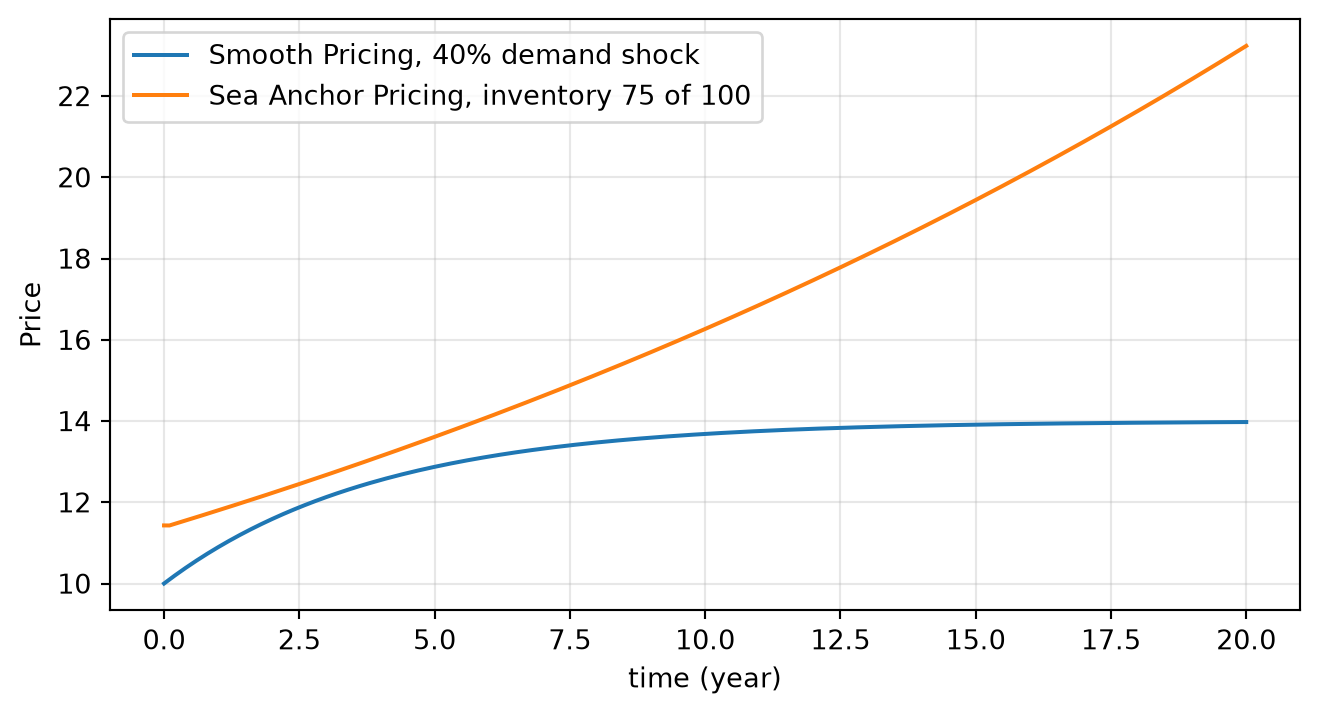

In [8]:
import pandas as pd
sp = lb.molecule("smoothPricing")
sa = lb.molecule("seaAnchorPricing")

fig, ax = plt.subplots(figsize=(8, 4))
smooth = sp.run(T=20, market_pressure=1.4)
anchor = sa.run(T=20, inventory=75)
smooth["Price"].plot(ax=ax, label="Smooth Pricing, 40% demand shock")
anchor["Price"].plot(ax=ax, label="Sea Anchor Pricing, inventory 75 of 100")
ax.set_ylabel("Price"); ax.legend(); ax.grid(alpha=0.3)

print(pd.DataFrame({"smooth": smooth["Price"], "anchor": anchor["Price"]}).loc[[0, 4, 10, 20]].round(2))

The smooth price goes from 10 towards its new target of 14: about 12.5 after one adjustment time of 4 years, and 13.97 by year 20, where it stays. The anchored price never stops. With inventory stuck at 75% of its target, each year's price is a markup on a reference that has itself crept up, so the price climbs from about 11.4 to 23.2 in 20 years. In a whole market that climb would not go on for ever: a high price would cut demand and bring new capacity, inventory would recover, and the pressure would reverse. But because capacity takes years to build, the reversal comes late and goes too far. That is how commodity cycles in metals, paper or livestock sustain themselves (see Sterman 2000, ch. 20).

**Try it.** In Sea Anchor Pricing with inventory 75, how long does the price take to double? What if traders take twice as long to change their idea of the normal price (`time_to_change_underlying_price=8`)?

<details><summary>Show a worked answer</summary>

The pressure is 2 / (1 + 0.75) ≈ 1.14, so the anchor rises about 14% / 4 ≈ 3.6% a year, and anything growing at 3.6% doubles in about 0.69 / 0.036 ≈ 19 years. The run says 19.6 years. With a time of 8, the growth rate halves and the doubling time roughly doubles, to 39 years. Slower anchors give slower, but still endless, drift.
</details>

In [9]:
for t in (4, 8):
    p = sa.run(T=40, time_to_change_underlying_price=t)["Price"]
    print(f"time to change {t}: price doubles by year {p.index[p >= 2 * p.iloc[0]][0]}")

time to change 4: price doubles by year 19.6
time to change 8: price doubles by year 39.0


## Where next

- Back in the app: the [Cycles module](https://waelrash1.github.io/loopbricks/#/learn/cycles) walks through the inventory and workforce cycle week by week and builds a commodity market loop by loop.
- The cycle in section 2 is the stock management structure from the [Oscillation module](https://waelrash1.github.io/loopbricks/#/learn/oscillation); the delays behind it are in [Delays and perception](https://waelrash1.github.io/loopbricks/#/learn/delays).
- How price setters and hiring managers form expectations is the subject of [Bounded rationality and expectations](https://waelrash1.github.io/loopbricks/#/learn/behaviour).